# Activity 2: Web Scraping

1. **An API**: the provider sends clean data on request (FRED).
2. **A web page**: the numbers are in an HTML table (Central Bank of Trinidad and Tobago).
3. **An Excel file**: the numbers are in a workbook made for people to read, not for programs
   (CBTT Economic Datapack).

Cells marked `<YOUR CODE HERE: ...>` are for you to complete. The solution is in
`sols/act2_scraping.ipynb`.

In [1]:
import requests
import pandas as pd
from bs4 import BeautifulSoup

C:\Users\guerr\anaconda3\envs\nwcst\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.4.1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


## Part 1. FRED: an API

FRED is the St. Louis Fed's database. You ask for **one series by its code** and get back
dates and values as JSON. The request is a URL with three parameters:

| parameter | value |
|---|---|
| `series_id` | the series code, found on the series page at fred.stlouisfed.org |
| `api_key` | a free personal key: https://fredaccount.stlouisfed.org/apikeys |
| `file_type` | `json` |

Everything needed is in the next cell: the key, the URL, the request and the conversion to a DataFrame.

In [2]:
API_KEY = "72304a91a13cc0ea6c610ae5845c7493"            # the instructor's key: get your own for later use
SERIES  = "DCOILBRENTEU"                                # Brent crude oil, US$ per barrel, daily

url = ("https://api.stlouisfed.org/fred/series/observations"
       f"?series_id={SERIES}&api_key={API_KEY}&file_type=json")

response = requests.get(url, timeout=60)               # send the request
print(response.status_code)                             # 200 = OK

obs = response.json()["observations"]                  # a list of {"date": ..., "value": ...}
df_fred = pd.DataFrame(obs)[["date", "value"]]
df_fred["date"]  = pd.to_datetime(df_fred["date"])
df_fred["value"] = pd.to_numeric(df_fred["value"], errors="coerce")   # FRED writes "." for missing
df_fred = df_fred.set_index("date").rename(columns={"value": SERIES})
df_fred.tail()

200


,DCOILBRENTEU
date,
2026-10-14,126.55
2026-10-15,126.35
2026-10-16,119.33
2026-10-19,118.82
2026-10-20,115.22


<Axes: title={'center': 'Brent crude oil, US$ per barrel'}, xlabel='date'>

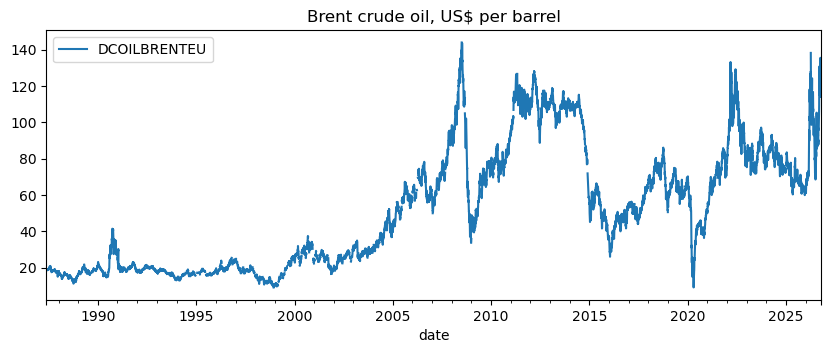

In [3]:
df_fred.plot(figsize=(10, 3.5), title="Brent crude oil, US$ per barrel")

Two series in a loop and merge them. Start with an empty dataframe

<Axes: xlabel='date'>

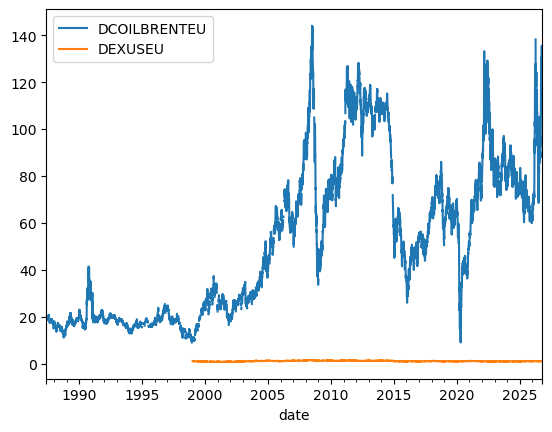

In [4]:
#<YOUR CODE HERE: download DEXUSEU and plot it>
df = pd.DataFrame()
SERIES  = ["DCOILBRENTEU", "DEXUSEU"]

for SERIE in SERIES :
    url = ("https://api.stlouisfed.org/fred/series/observations"
           f"?series_id={SERIE}&api_key={API_KEY}&file_type=json")

    response = requests.get(url, timeout=60)               # send the request

    obs = response.json()["observations"]                  # a list of {"date": ..., "value": ...}
    df_fred = pd.DataFrame(obs)[["date", "value"]]
    df_fred["date"]  = pd.to_datetime(df_fred["date"])
    df_fred["value"] = pd.to_numeric(df_fred["value"], errors="coerce")   # FRED writes "." for missing
    df_fred = df_fred.set_index("date").rename(columns={"value": SERIE})
    df = pd.concat([df, df_fred], axis=1)

df.plot()


## Part 2. A web page: the CBTT Data Centre

The Central Bank publishes its statistics as web pages, one table per page. We take the
**consumer price index** (monthly).

### Step 1: look before you code

Open the page in your browser:

https://www.central-bank.org.tt/data-center-block/?title=consumer-price-index-index-values-monthly&id=36

Right-click the table and choose **Inspect**. The table is a `<table id="table_1">`, the column
names are `<th>` cells inside `<thead>`, and each row of data is a `<tr>` inside `<tbody>`.

### Step 2: request the page

`headers` makes the request look like it comes from a browser. Many sites block requests without it.

In [5]:
url = "https://www.central-bank.org.tt/data-center-block/?title=consumer-price-index-index-values-monthly&id=36"
hdr = {"User-Agent": "Mozilla/5.0"}

r = requests.get(url, headers=hdr, timeout=60)
print(r.status_code)                       # 200 = OK, 403 = blocked, 404 = not found
print(r.headers["Content-Type"])           # text/html: a web page, not data

200
text/html; charset=UTF-8


### Step 3: html text

How does a website code look like?

In [6]:
print(r.text[:500])

<!DOCTYPE HTML>
<html lang="en-US" prefix="og: http://ogp.me/ns#">
<head>
	<meta charset="UTF-8">
	<meta name='robots' content='index, follow, max-image-preview:large, max-snippet:-1, max-video-preview:-1' />

	<!-- This site is optimized with the Yoast SEO plugin v28.6 - https://yoast.com/product/yoast-seo-wordpress/ -->
	<title>Data Center Block - Central Bank of Trinidad and Tobago</title>
	<link rel="canonical" href="https://www.central-bank.org.tt/data-center-block/" />
	<meta property=


### Step 4: find the table

`BeautifulSoup` turns the text into a tree we can search. `select_one("table#table_1")` means:
the `<table>` whose `id` is `table_1`.

In [7]:
soup  = BeautifulSoup(r.text, "html.parser")
table = soup.select_one("table#table_1")
print(str(table)[:500])

<table class="scroll responsive display nowrap wdt-no-display data-t data-t wpDataTable wpDataTableID-36" data-described-by="table_1_desc" data-wpdatatable_id="36" id="table_1" style="display: none; ">
<!-- Table header -->
<thead>
<tr>
<th class="wdtheader sort" data-class="expand" style="">        Date</th> <th class="wdtheader" style="">        Consumer Price Index - All Items - (Jan. 15 = 100)</th> <th class="wdtheader" style="">        Consumer Price Index - Food - (Jan. 15 = 100)</th> <th 


### Step 5: the column names

Every `<th>` inside `<thead>`. `get_text(strip=True)` keeps only the text, without tags or spaces.

In [8]:
cols = [th.get_text(strip=True) for th in table.select("thead th")]
print(len(cols), "columns")
cols[:4]

29 columns


['Date',
 'Consumer Price Index - All Items - (Jan. 15 = 100)',
 'Consumer Price Index - Food - (Jan. 15 = 100)',
 'Consumer Price Index - Core (Jan. 15 = 100)']

### Step 6: one row

Every `<tr>` inside `<tbody>` is a row, and every `<td>` inside it is a cell. Look at the first one.

In [9]:
rows_html = table.select("tbody tr")
print(len(rows_html), "rows")

first = [td.get_text(strip=True) for td in rows_html[0].select("td")]
first[:4]

430 rows


['30/10/2026', 'n.d.', 'n.d.', 'n.d.']

### Step 7: Get the rows

**COMPLETE**: repeat Step 6 for every row, then build the DataFrame.

In [10]:
rows = []
for tr in rows_html:
    rows.append([td.get_text(strip=True) for td in tr.select("td")])

df_cpi = pd.DataFrame(rows, columns=cols)
df_cpi.head()

,Date,Consumer Price Index - All Items - (Jan. 15 = 100),Consumer Price Index - Food - (Jan. 15 = 100),Consumer Price Index - Core (Jan. 15 = 100),Consumer Price Index - Bread and Cereals (Jan. 15 = 100),Consumer Price Index - Meat (Jan. 15 = 100),Consumer Price Index - Fish (Jan. 15 = 100),"Consumer Price Index - Milk, Cheese and Eggs (Jan. 15 = 100)",Consumer Price Index - Oils and Fats (Jan. 15 = 100),Consumer Price Index - Fruits (Jan. 15 = 100),...,Consumer Price Index - Imputed Rent - (Jan. 15 = 100),"Consumer Price Index - Water, Electricity, Gas and Other Fuels - (Jan. 15 = 100)",Consumer Price Index - Transportation (Jan. 15 = 100),"Consumer Price Index - Furnishings, Household Equipment and Routine Maintenance of the House (Jan. 15 = 100)",Consumer Price Index - Recreation and Culture (Jan. 15 = 100),"Consumer Price Index - Hotels, Cafes and Restaurants (Jan. 15 = 100)",Consumer Price Index - Miscellaneous Goods and Services (Jan. 15 = 100),Consumer Price Index - All Items - (Jan. 15 = 100) - Tobago,Consumer Price Index - Food - (Jan. 15 = 100) - Tobago,Consumer Price Index - Core - (Jan. 15 = 100) - Tobago
0,30/10/2026,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,...,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.
1,30/09/2026,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,...,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.
2,31/08/2026,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,...,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.
3,31/07/2026,126.4,157.2,119.9,n.d.,n.d.,n.d.,n.d.,n.d.,n.d.,...,n.d.,n.d.,124.0,113.1,123.7,142.8,128.7,n.d.,n.d.,n.d.
4,30/06/2026,126.0,156.9,119.6,143.6,166.0,143.4,142.5,168.7,162.8,...,115.5,100.7,124.0,112.6,122.2,142.2,128.4,129.6,152.8,126.1


### Step 8: clean

Everything arrived as **text**. Dates are written day first (`31/01/1991`), and the bank writes
`n.d.` where there is no data. `errors="coerce"` turns anything that is not a number into `NaN`.
The rows are not in date order on the page, so sort them.

In [11]:
df_cpi["Date"] = pd.to_datetime(df_cpi["Date"], dayfirst=True)
df_cpi = df_cpi.set_index("Date").sort_index()
df_cpi = df_cpi.apply(pd.to_numeric, errors="coerce")
df_cpi.dtypes.head()

Consumer Price Index - All Items - (Jan. 15 = 100)          float64
Consumer Price Index - Food - (Jan. 15 = 100)               float64
Consumer Price Index - Core (Jan. 15 = 100)                 float64
Consumer Price Index - Bread and Cereals (Jan. 15 = 100)    float64
Consumer Price Index - Meat (Jan. 15 = 100)                 float64
dtype: object

Show the result

In [12]:
df_cpi

,Consumer Price Index - All Items - (Jan. 15 = 100),Consumer Price Index - Food - (Jan. 15 = 100),Consumer Price Index - Core (Jan. 15 = 100),Consumer Price Index - Bread and Cereals (Jan. 15 = 100),Consumer Price Index - Meat (Jan. 15 = 100),Consumer Price Index - Fish (Jan. 15 = 100),"Consumer Price Index - Milk, Cheese and Eggs (Jan. 15 = 100)",Consumer Price Index - Oils and Fats (Jan. 15 = 100),Consumer Price Index - Fruits (Jan. 15 = 100),Consumer Price Index - Vegetables (Jan. 15 = 100),...,Consumer Price Index - Imputed Rent - (Jan. 15 = 100),"Consumer Price Index - Water, Electricity, Gas and Other Fuels - (Jan. 15 = 100)",Consumer Price Index - Transportation (Jan. 15 = 100),"Consumer Price Index - Furnishings, Household Equipment and Routine Maintenance of the House (Jan. 15 = 100)",Consumer Price Index - Recreation and Culture (Jan. 15 = 100),"Consumer Price Index - Hotels, Cafes and Restaurants (Jan. 15 = 100)",Consumer Price Index - Miscellaneous Goods and Services (Jan. 15 = 100),Consumer Price Index - All Items - (Jan. 15 = 100) - Tobago,Consumer Price Index - Food - (Jan. 15 = 100) - Tobago,Consumer Price Index - Core - (Jan. 15 = 100) - Tobago
Date,,,,,,,,,,,,,,,,,,,,,
1991-01-31,23.6,4.1,56.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,59.0,66.9,46.4,74.6,44.1,38.4,43.8,NaN,NaN,NaN
1991-02-28,23.5,4.1,56.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,59.4,66.8,46.4,74.6,44.1,38.4,43.8,NaN,NaN,NaN
1991-03-31,23.5,4.1,56.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,59.3,66.8,46.4,74.6,44.1,38.4,43.8,NaN,NaN,NaN
1991-04-30,23.5,4.1,56.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,59.2,66.8,46.2,74.9,44.1,38.3,43.8,NaN,NaN,NaN
1991-05-31,23.7,4.2,56.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,59.1,66.9,46.2,74.9,44.1,38.3,43.9,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-06-30,126.0,156.9,119.6,143.6,166.0,143.4,142.5,168.7,162.8,162.5,...,115.5,100.7,124.0,112.6,122.2,142.2,128.4,129.6,152.8,126.1
2026-07-31,126.4,157.2,119.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,124.0,113.1,123.7,142.8,128.7,NaN,NaN,NaN
2026-08-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Part 3. An Excel file: the CBTT Economic Datapack

The Central Bank's **Economic Datapack** is one workbook with most of its statistics, linked from

https://www.central-bank.org.tt/resources-category/publications-and-research/all-reports/economic-datapack-report/

Workbooks like this are made to be read by people: titles, notes, headers over several rows,
empty columns between blocks. We clean one sheet step by step, looking at it after each step.

### Step 1: download the file

When the address is a file, `requests.get` returns the file itself. Save it to disk.

In [13]:
xl_url = "https://www.central-bank.org.tt/wp-content/uploads/2026/10/edp-download-september-2026.xlsm"

r = requests.get(xl_url, headers=hdr, timeout=120)
print(r.status_code, f"{len(r.content):,} bytes")

with open("../raw/cbtt_datapack.xlsm", "wb") as f:
    f.write(r.content)

200 1,041,911 bytes


### Step 2: list the sheets

`pd.ExcelFile` opens the workbook without reading every sheet.

In [14]:
xls = pd.ExcelFile("../raw/cbtt_datapack.xlsm")
xls.sheet_names

['Index',
 'PAGE 4_Intl&Regl_Monthly',
 'PAGE 4_Intl&Regl_Quarterly',
 'FAME Persistence2',
 'PAGE 5_DomesticAct_Quarterly',
 'PAGE 6_DomesticInd_Quarterly',
 'PAGE 7_PriceIndices_Monthly',
 'PAGE 7_PriceIndices_Quarterly',
 'PAGE 8_Comm.Prices_Monthly',
 'PAGE 8_Comm.Prod_Quarterly',
 'PAGE 9_LabMkt_Quarterly',
 'PAGE 10_Fiscal_Quarterly',
 'PAGE 10_Fiscal_FY',
 'PAGE 11_Debt_Quarterly',
 'PAGE 12_Liquidity_Monthly',
 'PAGE 13_Int.Rates_Quarterly',
 'PAGE 14_MonAggs_Monthly',
 'PAGE 14_MonAggs_Annual',
 'PAGE 15_BondMkt_Quarterly',
 'PAGE 15_BondMkt_Yields_Monthly',
 'PAGE 16_CapMkt_Quarterly',
 'PAGE 16_CapMkt_Monthly',
 'PAGE 17_EXT_BOP_Quarterly',
 'PAGE 18_EXT_IIP&QEDS_Quarterly',
 'PAGE 19_Forex_Monthly',
 'PAGE 20_Reserves_Monthly']

### Step 3: read one sheet as it is

`PAGE 5_DomesticAct_Quarterly` holds the quarterly GDP growth. `header=None` reads every row as
data, so we see the sheet exactly as it looks in Excel.

In [15]:
raw = pd.read_excel(xls, sheet_name="PAGE 5_DomesticAct_Quarterly", header=None)
print(raw.shape)
raw.iloc[:14, :6]

(153, 22)


,0,1,2,3,4,5
0,NaN,REAL SECTOR - DOMESTIC ECONOMIC ACTIVITY,NaN,NaN,NaN,NaN
1,Unit,Per Cent,Per Cent,Per Cent,Per Cent,Per Cent
2,Frequency,Quarterly,Quarterly,Quarterly,Quarterly,Quarterly
3,Source,Central Statistical Office,Central Statistical Office,Central Statistical Office,Central Statistical Office,Central Statistical Office
4,Series Start,2013-03-01 00:00:00,2013-03-01 00:00:00,2013-03-01 00:00:00,2013-03-01 00:00:00,2013-03-01 00:00:00
5,Series End,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00
6,No. of Observations,52,52,52,52,52
7,Series Descriptions,QGDP - Total,QGDP - Energy,QGDP - Non-Energy,QGDP - Non-Energy: Construction,QGDP - Non-Energy: Trade and Repairs (excl. En...
8,Date,Quarterly Gross Domestic Product (QGDP),NaN,NaN,NaN,NaN
9,NaN,Total,Energy,Non-Energy,of which:,NaN


Rows 0 to 6 are a description (unit, frequency, source, ...). Row 7, `Series Descriptions`, has
one clean name per column. Rows 8 to 10 are the header as people see it, spread over three rows.
The data start at row 11.

### Step 4: use row 7 as the column names

In [16]:
df_xl = raw.copy()
df_xl.columns = raw.iloc[7].tolist()
df_xl.iloc[:14, :6]

,Series Descriptions,QGDP - Total,QGDP - Energy,QGDP - Non-Energy,QGDP - Non-Energy: Construction,QGDP - Non-Energy: Trade and Repairs (excl. Energy)
0,NaN,REAL SECTOR - DOMESTIC ECONOMIC ACTIVITY,NaN,NaN,NaN,NaN
1,Unit,Per Cent,Per Cent,Per Cent,Per Cent,Per Cent
2,Frequency,Quarterly,Quarterly,Quarterly,Quarterly,Quarterly
3,Source,Central Statistical Office,Central Statistical Office,Central Statistical Office,Central Statistical Office,Central Statistical Office
4,Series Start,2013-03-01 00:00:00,2013-03-01 00:00:00,2013-03-01 00:00:00,2013-03-01 00:00:00,2013-03-01 00:00:00
5,Series End,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00
6,No. of Observations,52,52,52,52,52
7,Series Descriptions,QGDP - Total,QGDP - Energy,QGDP - Non-Energy,QGDP - Non-Energy: Construction,QGDP - Non-Energy: Trade and Repairs (excl. En...
8,Date,Quarterly Gross Domestic Product (QGDP),NaN,NaN,NaN,NaN
9,NaN,Total,Energy,Non-Energy,of which:,NaN


### Step 5: keep only the data rows

In [17]:
df_xl = df_xl.iloc[11:]
df_xl.head()

,Series Descriptions,QGDP - Total,QGDP - Energy,QGDP - Non-Energy,QGDP - Non-Energy: Construction,QGDP - Non-Energy: Trade and Repairs (excl. Energy),QGDP - Non-Energy: Manufacturing (excl. Refining and Petrochemical),QGDP - Non-Energy: Financial and Insurance Activities,NaN,QIEA - Total,...,QIEA - Non-Energy: Construction,QIEA - Non-Energy: Manufacturing (excl. Refining and Petrochemical),QIEA - Non-Energy: Wholesale and Retail Trade (excl. Energy),QIEA - Non-Energy: Agriculture,NaN,Capacity Utilisation - Manufacturing,"Capacity Utilisation - Manufacturing: Food, Beverages and Tobacco Products","Capacity Utilisation - Manufacturing: Textiles, Clothing, Leather, Wood, Paper and Printing",Capacity Utilisation - Manufacturing: Chemical Products,Capacity Utilisation - Manufacturing: Other Manufactured Products
11,1991-03-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,1991-06-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,1991-09-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,1991-12-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,1992-03-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Step 6: the dates as the index

The first column holds the dates. Each quarter is dated by the first day of its last month (March, June, ...).

In [18]:
df_xl = df_xl.rename(columns={"Series Descriptions": "date"})
df_xl["date"] = pd.to_datetime(df_xl["date"])
df_xl = df_xl.set_index("date")
df_xl.head()

,QGDP - Total,QGDP - Energy,QGDP - Non-Energy,QGDP - Non-Energy: Construction,QGDP - Non-Energy: Trade and Repairs (excl. Energy),QGDP - Non-Energy: Manufacturing (excl. Refining and Petrochemical),QGDP - Non-Energy: Financial and Insurance Activities,NaN,QIEA - Total,QIEA - Energy,...,QIEA - Non-Energy: Construction,QIEA - Non-Energy: Manufacturing (excl. Refining and Petrochemical),QIEA - Non-Energy: Wholesale and Retail Trade (excl. Energy),QIEA - Non-Energy: Agriculture,NaN,Capacity Utilisation - Manufacturing,"Capacity Utilisation - Manufacturing: Food, Beverages and Tobacco Products","Capacity Utilisation - Manufacturing: Textiles, Clothing, Leather, Wood, Paper and Printing",Capacity Utilisation - Manufacturing: Chemical Products,Capacity Utilisation - Manufacturing: Other Manufactured Products
date,,,,,,,,,,,,,,,,,,,,,
1991-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1991-06-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1991-09-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1991-12-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1992-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Step 7: drop the empty columns and rows

The sheet has empty columns between blocks, and the early quarters and the latest ones have no data.
**COMPLETE**: `dropna(how="all")` drops a row only if every value in it is missing; `axis=1` does the same for columns.

In [19]:
df_xl = df_xl.dropna(how="all", axis=1)
df_xl = df_xl.dropna(how="all", axis=0)
print(df_xl.shape)
df_xl.head()

(70, 19)


,QGDP - Total,QGDP - Energy,QGDP - Non-Energy,QGDP - Non-Energy: Construction,QGDP - Non-Energy: Trade and Repairs (excl. Energy),QGDP - Non-Energy: Manufacturing (excl. Refining and Petrochemical),QGDP - Non-Energy: Financial and Insurance Activities,QIEA - Total,QIEA - Energy,QIEA - Non-Energy,QIEA - Non-Energy: Construction,QIEA - Non-Energy: Manufacturing (excl. Refining and Petrochemical),QIEA - Non-Energy: Wholesale and Retail Trade (excl. Energy),QIEA - Non-Energy: Agriculture,Capacity Utilisation - Manufacturing,"Capacity Utilisation - Manufacturing: Food, Beverages and Tobacco Products","Capacity Utilisation - Manufacturing: Textiles, Clothing, Leather, Wood, Paper and Printing",Capacity Utilisation - Manufacturing: Chemical Products,Capacity Utilisation - Manufacturing: Other Manufactured Products
date,,,,,,,,,,,,,,,,,,,
2009-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,67.5749,70.2464,74.20261,65.1741,46.65917
2009-06-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,67.7092,70.4913,69.4439,65.19,56.76487
2009-09-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,66.8764,68.0307,67.52608,67.4955,59.6574
2009-12-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.8993,71.8974,79.71918,64.3034,59.49113
2010-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.7727,67.1217,63.26899,59.6379,66.84298


### Step 8: Formatting

The columns came from mixed rows (text and numbers), so pandas stored them as `object`. Convert them.

In [20]:
print(df_xl.dtypes.head(3))
df_xl = df_xl.apply(pd.to_numeric, errors="coerce")
df_xl.dtypes.head(3)

QGDP - Total         object
QGDP - Energy        object
QGDP - Non-Energy    object
dtype: object


QGDP - Total         float64
QGDP - Energy        float64
QGDP - Non-Energy    float64
dtype: object

GDP growth here is the change against the same quarter a year earlier, in per cent.
**COMPLETE**: plot total, energy and non-energy GDP growth.

<Axes: title={'center': 'Real GDP growth, % year on year'}, xlabel='date'>

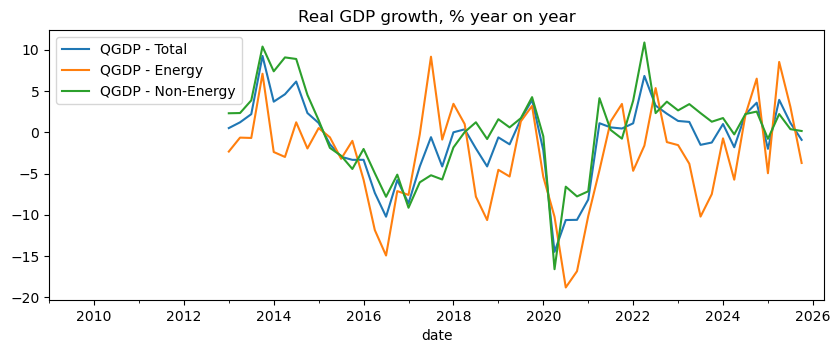

In [21]:
df_xl[["QGDP - Total", "QGDP - Energy", "QGDP - Non-Energy"]].plot(figsize=(10, 3.5), title="Real GDP growth, % year on year")